# 위고비 상품조건 비교

지급액·지급한도에 따른 목표이익률 10% 월 보험료와, 보험료를 고정했을 때의 주요 스트레스 시나리오 이익률을 비교한다.  
이 노트북은 저장된 상품조건 비교 CSV만 읽으며 보험료와 현금흐름을 다시 산출하지 않는다.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
font_candidates = ["Arial Unicode MS", "AppleGothic", "Noto Sans CJK KR", "NanumGothic", "Malgun Gothic"]
korean_font = next((font for font in font_candidates if font in available_fonts), None)
if korean_font is None:
    raise RuntimeError("한글 글꼴을 찾지 못했습니다. AppleGothic, Arial Unicode MS 또는 Noto Sans CJK KR를 확인하세요.")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": korean_font,
    "axes.unicode_minus": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "figure.dpi": 120,
})
print(f"한글 글꼴: {korean_font}")

한글 글꼴: Arial Unicode MS


## 1. 결과 CSV 불러오기·검증

저장소 루트를 자동으로 찾고, 10% 가격 행과 요청한 세 스트레스만 분리한다. 누락·중복·단위 오류가 있으면 그래프를 그리기 전에 중단한다.

In [2]:
def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    markers = [Path("config/product_comparison.json"), Path("models/rider/product_comparison.py")]
    for anchor in [start, *start.parents]:
        for candidate in (anchor, anchor / "glp1_pricing_analysis"):
            if all((candidate / marker).exists() for marker in markers):
                return candidate.resolve()
    raise FileNotFoundError("저장소 루트를 찾지 못했습니다. glp1_pricing_analysis 내부 또는 상위 폴더에서 실행하세요.")

repo_root = find_repo_root()
output_dir = repo_root / "outputs/product_comparison"
figure_dir = output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

csv_paths = {
    "pricing": output_dir / "design_pricing_benefit_comparison.csv",
    "stress": output_dir / "stress_detail_342_results.csv",
    "decision": output_dir / "decision_summary.csv",
}
missing = [str(path.relative_to(repo_root)) for path in csv_paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "상품조건 비교 결과 CSV가 없습니다. 먼저 저장소 루트에서 "
        "`python -m models.rider.product_comparison --stage full`을 실행하세요.\n"
        + "누락 파일: " + ", ".join(missing)
    )

pricing = pd.read_csv(csv_paths["pricing"])
stress = pd.read_csv(csv_paths["stress"])
decision = pd.read_csv(csv_paths["decision"])

required_columns = {
    "pricing": {"design_id", "benefit_per_dispense_krw", "max_claims", "waiting_days",
                "decision_horizon_units", "target_profit_margin", "monthly_gross_premium_rounded_up_krw"},
    "stress": {"design_id", "benefit_per_dispense_krw", "max_claims", "target_profit_margin",
               "analysis_group", "experience_scenario_id", "premium_income_pv_krw",
               "profit_pv_krw", "scenario_profit_margin"},
    "decision": {"design_id", "target_profit_margin", "monthly_gross_premium_rounded_up_krw"},
}
for name, frame in {"pricing": pricing, "stress": stress, "decision": decision}.items():
    absent = required_columns[name] - set(frame.columns)
    assert not absent, f"{name} CSV 필수 열 누락: {sorted(absent)}"

target_margin = 0.10
pricing_10 = pricing.loc[np.isclose(pricing["target_profit_margin"], target_margin)].copy()
assert len(pricing_10) == 9 and pricing_10["design_id"].nunique() == 9, "10% 보험료 데이터는 정확히 9개 설계여야 합니다."
assert np.isclose(pricing_10["target_profit_margin"], target_margin).all(), "10% 외 가격 행이 포함됐습니다."
rounded_premium = pricing_10["monthly_gross_premium_rounded_up_krw"]
assert rounded_premium.notna().all() and np.isclose(rounded_premium, np.ceil(rounded_premium)).all(), "확정 보험료가 원 단위 올림 금액이 아닙니다."
baseline_premium = pricing_10.loc[
    np.isclose(pricing_10["benefit_per_dispense_krw"], 100_000) & pricing_10["max_claims"].eq(13),
    "monthly_gross_premium_rounded_up_krw",
].squeeze()
assert baseline_premium == 3_141, f"기준 상품 보험료가 3,141원이 아닙니다: {baseline_premium:,.0f}원"

scenario_specs = [
    ("지원반응 증가", "start_rate", "response_high"),
    ("시작률 복합 스트레스", "start_rate", "combined_stress"),
    ("치료 행태 복합 스트레스", "treatment_behavior", "treatment_combined_stress"),
]
stress_10 = stress.loc[np.isclose(stress["target_profit_margin"], target_margin)].copy()
heat_parts = []
for column_label, analysis_group, scenario_id in scenario_specs:
    part = stress_10.loc[
        stress_10["analysis_group"].eq(analysis_group)
        & stress_10["experience_scenario_id"].eq(scenario_id)
    ].copy()
    part["heatmap_column"] = column_label
    heat_parts.append(part)
heat_data = pd.concat(heat_parts, ignore_index=True)

assert len(heat_data) == 27, f"히트맵 데이터는 27행이어야 합니다: {len(heat_data)}행"
assert heat_data["design_id"].nunique() == 9, "히트맵에 9개 설계가 모두 있어야 합니다."
assert not heat_data.duplicated(["design_id", "heatmap_column"]).any(), "설계·시나리오 중복이 있습니다."
assert np.isclose(heat_data["target_profit_margin"], target_margin).all(), "10% 외 스트레스 행이 포함됐습니다."
assert heat_data["scenario_profit_margin"].abs().max() < 1, "시나리오 이익률은 백분율이 아니라 소수여야 합니다."
recalculated_margin = heat_data["profit_pv_krw"] / heat_data["premium_income_pv_krw"]
margin_error = (heat_data["scenario_profit_margin"] - recalculated_margin).abs().max()
assert np.allclose(heat_data["scenario_profit_margin"], recalculated_margin, rtol=0, atol=1e-12), "저장 이익률과 손익/보험료 수입이 다릅니다."

treatment_config = json.loads((repo_root / "config/treatment_scenarios.json").read_text(encoding="utf-8"))
treatment_stress = next(item for item in treatment_config["scenarios"] if item["scenario_id"] == "treatment_combined_stress")
assert treatment_stress["overrides"] == {
    "stop_reduction": 0.2,
    "restart_in_window_fraction": 0.4,
    "postrestart_stop_hazard_multiplier": 0.75,
}, "치료 행태 복합 스트레스 설정이 요청 조건과 다릅니다."

validation = pd.DataFrame({
    "검증 항목": ["보험료 설계 수", "히트맵 행 수", "목표이익률", "기준 상품 보험료", "이익률 최대 대조 오차", "치료 행태 시나리오 ID"],
    "결과": ["9개", "27개 (9×3)", "10%만 포함", f"{baseline_premium:,.0f}원", f"{margin_error:.2e}", treatment_stress["scenario_id"]],
})
display(validation)
display(pricing_10[["design_id", "benefit_per_dispense_krw", "max_claims", "monthly_gross_premium_rounded_up_krw"]]
        .sort_values(["benefit_per_dispense_krw", "max_claims"]).reset_index(drop=True))

,검증 항목,결과
0,보험료 설계 수,9개
1,히트맵 행 수,27개 (9×3)
2,목표이익률,10%만 포함
3,기준 상품 보험료,"3,141원"
4,이익률 최대 대조 오차,1.11e-16
5,치료 행태 시나리오 ID,treatment_combined_stress


,design_id,benefit_per_dispense_krw,max_claims,monthly_gross_premium_rounded_up_krw
0,benefit100k_max6_wait90,"100,000.0000",6,2051
1,benefit100k_max13_wait90,"100,000.0000",13,3141
2,benefit100k_max26_wait90,"100,000.0000",26,4256
3,benefit150k_max6_wait90,"150,000.0000",6,2714
4,benefit150k_max13_wait90,"150,000.0000",13,4372
5,benefit150k_max26_wait90,"150,000.0000",26,6053
6,benefit200k_max6_wait90,"200,000.0000",6,3384
7,benefit200k_max13_wait90,"200,000.0000",13,5638
8,benefit200k_max26_wait90,"200,000.0000",26,7901


## 2. 월 보험료 비교

목표이익률 10%로 산출한 원 단위 올림 월 보험료를 지급한도와 조제당 지급액별로 비교한다.

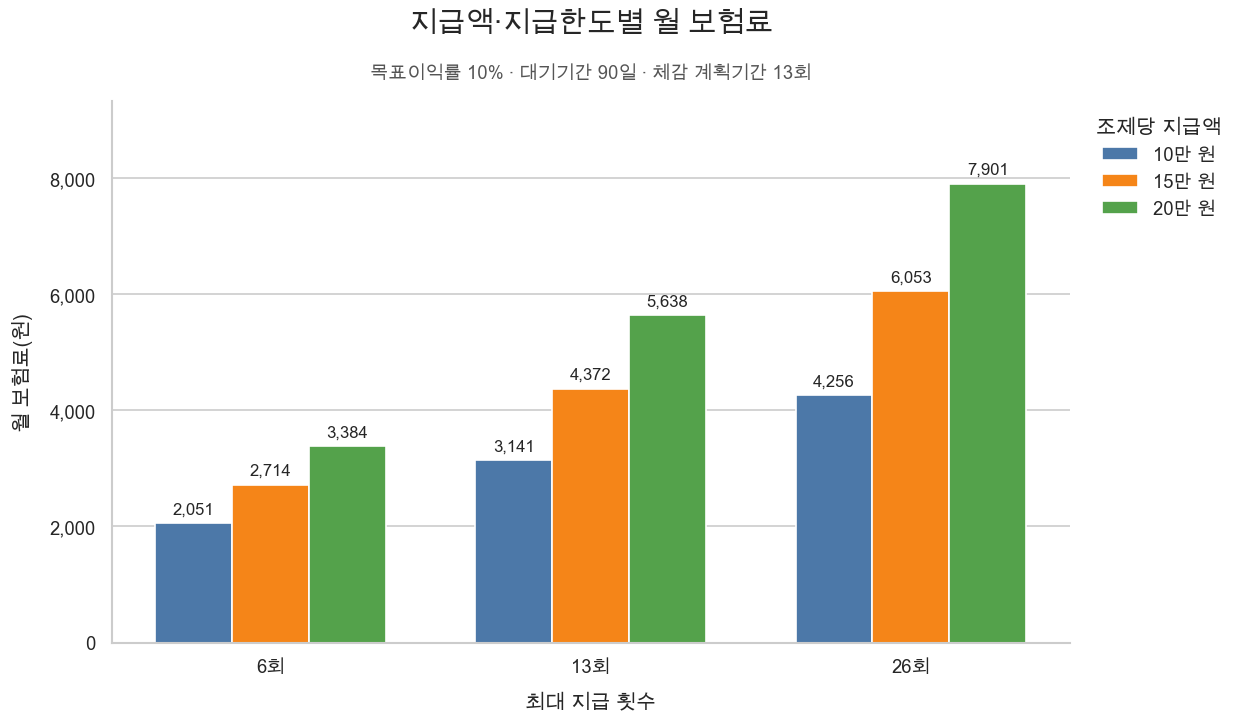

**실제 결과.** 보험료는 10만 원·6회의 **2,051원**에서 20만 원·26회의 **7,901원**까지 높아진다. 지급액과 지급한도가 커질수록 월 보험료도 일관되게 증가한다.

In [3]:
claim_order = [6, 13, 26]
benefit_order = [100_000, 150_000, 200_000]
benefit_labels = {100_000: "10만 원", 150_000: "15만 원", 200_000: "20만 원"}
benefit_colors = {100_000: "#4C78A8", 150_000: "#F58518", 200_000: "#54A24B"}

premium_matrix = (pricing_10.pivot(index="max_claims", columns="benefit_per_dispense_krw",
                                   values="monthly_gross_premium_rounded_up_krw")
                  .reindex(index=claim_order, columns=benefit_order))
assert premium_matrix.notna().all().all(), "보험료 그래프에 누락된 설계가 있습니다."

fig, ax = plt.subplots(figsize=(10.5, 6.2))
x = np.arange(len(claim_order))
bar_width = 0.24
for idx, benefit in enumerate(benefit_order):
    positions = x + (idx - 1) * bar_width
    bars = ax.bar(positions, premium_matrix[benefit], width=bar_width,
                  color=benefit_colors[benefit], label=benefit_labels[benefit])
    ax.bar_label(bars, labels=[f"{value:,.0f}" for value in premium_matrix[benefit]],
                 padding=4, fontsize=10)

ax.set_title("지급액·지급한도별 월 보험료", fontsize=17, weight="bold", pad=42)
ax.text(0.5, 1.035, "목표이익률 10% · 대기기간 90일 · 체감 계획기간 13회",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=11, color="#555555")
ax.set_xlabel("최대 지급 횟수", labelpad=10)
ax.set_ylabel("월 보험료(원)", labelpad=10)
ax.set_xticks(x, [f"{claims}회" for claims in claim_order])
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.set_ylim(0, premium_matrix.to_numpy().max() * 1.18)
ax.legend(title="조제당 지급액", loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.tight_layout()
premium_figure_path = figure_dir / "product_premium_comparison_target10.png"
fig.savefig(premium_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

premium_min = premium_matrix.loc[6, 100_000]
premium_max = premium_matrix.loc[26, 200_000]
display(Markdown(
    f"**실제 결과.** 보험료는 10만 원·6회의 **{premium_min:,.0f}원**에서 "
    f"20만 원·26회의 **{premium_max:,.0f}원**까지 높아진다. 지급액과 지급한도가 커질수록 월 보험료도 일관되게 증가한다."
))

## 3. 스트레스 이익률 비교

각 상품의 10% 목표이익률 보험료를 고정한 뒤, 시작률 스트레스와 치료 행태 스트레스를 각각 적용한 시나리오 이익률(`손익 현가 / 총 보험료 수입 현가`)을 비교한다.

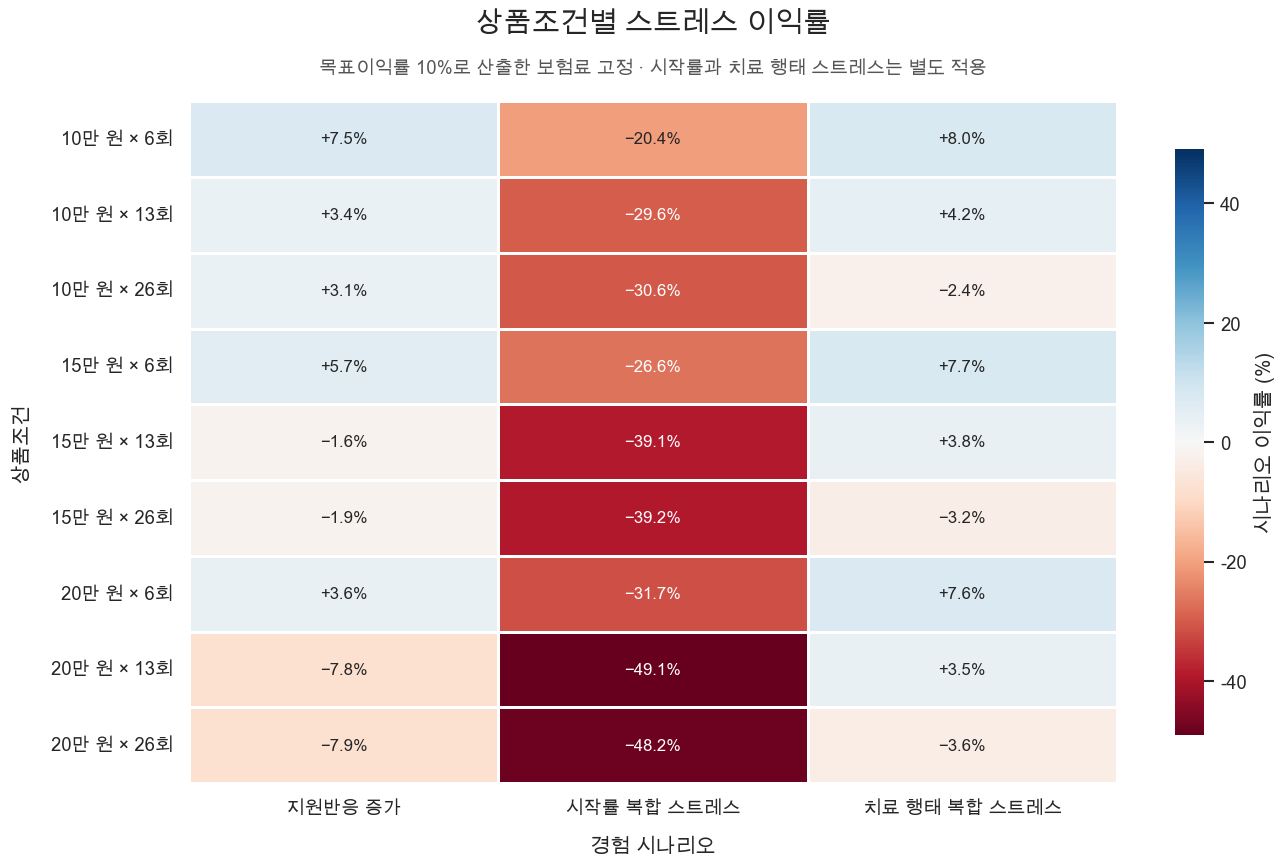

**실제 결과.** 시작률 복합 스트레스는 9개 설계가 모두 적자이며, 지원반응 증가에서는 **4개**, 치료 행태 복합 스트레스에서는 **3개** 설계가 적자다. 색상은 손익 금액이 아니라 시나리오 이익률을 나타낸다.

In [4]:
design_order = [(benefit, claims) for benefit in benefit_order for claims in claim_order]
design_labels = [f"{benefit // 10_000}만 원 × {claims}회" for benefit, claims in design_order]
scenario_order = [spec[0] for spec in scenario_specs]

heat_data["design_key"] = list(zip(heat_data["benefit_per_dispense_krw"].astype(int), heat_data["max_claims"].astype(int)))
heat_matrix = (heat_data.pivot(index="design_key", columns="heatmap_column", values="scenario_profit_margin")
               .reindex(index=design_order, columns=scenario_order))
assert heat_matrix.shape == (9, 3) and heat_matrix.notna().all().all(), "히트맵은 누락 없이 9×3이어야 합니다."

heat_percent = heat_matrix * 100  # CSV의 소수 이익률을 표시용 백분율로 한 번만 변환
heat_percent.index = design_labels
heat_percent.index.name = None
heat_percent.columns.name = None
annotations = heat_percent.map(lambda value: f"+{value:.1f}%" if value >= 0 else f"−{abs(value):.1f}%")
color_limit = float(np.abs(heat_percent.to_numpy()).max())

fig, ax = plt.subplots(figsize=(11.5, 7.4))
sns.heatmap(heat_percent, annot=annotations, fmt="", cmap="RdBu", center=0,
            vmin=-color_limit, vmax=color_limit, linewidths=0.8, linecolor="white",
            cbar_kws={"label": "시나리오 이익률 (%)", "shrink": 0.86}, ax=ax,
            annot_kws={"fontsize": 10, "weight": "bold"})
ax.set_title("상품조건별 스트레스 이익률", fontsize=17, weight="bold", pad=42)
ax.text(0.5, 1.035, "목표이익률 10%로 산출한 보험료 고정 · 시작률과 치료 행태 스트레스는 별도 적용",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=11, color="#555555")
ax.set_xlabel("경험 시나리오", labelpad=12)
ax.set_ylabel("상품조건", labelpad=12)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
heatmap_figure_path = figure_dir / "product_stress_margin_heatmap_target10.png"
fig.savefig(heatmap_figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

negative_counts = (heat_percent < 0).sum()
display(Markdown(
    f"**실제 결과.** 시작률 복합 스트레스는 9개 설계가 모두 적자이며, "
    f"지원반응 증가에서는 **{negative_counts['지원반응 증가']}개**, "
    f"치료 행태 복합 스트레스에서는 **{negative_counts['치료 행태 복합 스트레스']}개** 설계가 적자다. "
    f"색상은 손익 금액이 아니라 시나리오 이익률을 나타낸다."
))

## 4. 결과 해석

- 지급액과 지급한도를 늘리면 소비자 보장은 커지지만 월 보험료도 함께 상승한다.
- 시작률 복합 스트레스는 모든 설계에서 10% 가격 여유를 넘어 가장 뚜렷한 적자를 만든다.
- 지원반응 증가에는 6회 설계가 상대적으로 견고하고, 지급액이 큰 13·26회 설계는 적자로 전환한다.
- 치료 행태 복합 스트레스는 6·13회 설계보다 26회 설계에 더 불리하다. 두 스트레스군은 별도 적용했으므로 결합 효과로 해석하지 않는다.